# 05_XROMY_plot_maps

Simple plotting notebook with two subplots:

- **(a)** ROMY and G-ring shown in a surrounding regional frame.
- **(b)** ROMY array stations loaded from XML files in `metadata/`, with station distances (m) in grey next to labels.

## Notebook Overview
This notebook creates map visualizations of station/event geometry and analysis context for ROMY studies.

**Main workflow**
- Load station/event coordinate metadata.
- Prepare map baselayers and geographic context.
- Plot array/station/event geometry.
- Add annotations and optional overlays.
- Export map figures for reports/presentations.

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt

from obspy import read_inventory
from obspy.geodetics import gps2dist_azimuth


In [6]:
# Publication-style defaults
plt.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 200,
})

In [7]:
METADATA_DIR = "./metadata"

# Defined stations for panel (a)
stations_a = ["BW.ROMY", "BW.RLAS"]

# Defined stations for panel (b)
array_stations = ["BW.TON", "BW.BIB", "BW.GRMB", "BW.GELB", "BW.ALFT", "BW.ROMY"]


def xml_path_from_code(code):
    net, sta = code.split(".")
    return os.path.join(METADATA_DIR, f"station_{net}_{sta}.xml")


def load_station_latlon(code):
    path = xml_path_from_code(code)
    inv = read_inventory(path)
    sta = inv[0][0]
    return float(sta.latitude), float(sta.longitude)


# Load coordinates from XML metadata for both station lists
all_codes = sorted(set(stations_a + array_stations))
STATION_COORDS = {code: load_station_latlon(code) for code in all_codes}

# Distances relative to reference station (meters) for panel (b)
ref_code = "BW.ROMY"
ref_lat, ref_lon = STATION_COORDS[ref_code]
DIST_M = {}
for code in array_stations:
    lat, lon = STATION_COORDS[code]
    dist_m, _, _ = gps2dist_azimuth(ref_lat, ref_lon, lat, lon)
    DIST_M[code] = dist_m

print("stations (a):", stations_a)
print("array stations (b):", array_stations)
print("loaded from:", METADATA_DIR)

stations (a): ['BW.ROMY', 'BW.RLAS']
array stations (b): ['BW.TON', 'BW.BIB', 'BW.GRMB', 'BW.GELB', 'BW.ALFT', 'BW.ROMY']
loaded from: ./metadata


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import rasterio
import cartopy.crs as ccrs

proj = ccrs.PlateCarree()

# DEM for ROMY area (30 m)
DEM_PATH = "./data/ROMY_30m_DEM.tif"


def hillshade_grey(elev, vert_exag=0.3, azdeg=315, altdeg=45):
    """2D elevation -> soft grey hillshade."""
    ls = LightSource(azdeg=azdeg, altdeg=altdeg)
    hs = ls.hillshade(np.ma.masked_invalid(elev), vert_exag=vert_exag)
    return hs


def add_dem_light_grey(ax, geotiff_path=DEM_PATH, alpha=0.55, cmap="Greys_r"):
    with rasterio.open(geotiff_path) as src:
        elev = src.read(1).astype(float)
        nodata = src.nodata
        if nodata is not None:
            elev[elev == nodata] = np.nan
        bounds = src.bounds
    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
    hs = hillshade_grey(elev)
    im = ax.imshow(
        hs,
        origin="upper",
        extent=extent,
        transform=proj,
        cmap=cmap,
        vmin=0,
        vmax=1,
        alpha=alpha,
        zorder=0,
    )
    return im


# After ax.set_extent(...):
# add_dem_light_grey(ax1, alpha=0.45)
# add_dem_light_grey(ax2, alpha=0.45)   # if the GeoTIFF covers panel (b) extent too

In [9]:
import numpy as np

def add_curved_country_label(ax, text, center_lon, center_lat, radius_deg=0.45,
                             theta0=np.deg2rad(200), theta1=np.deg2rad(340),
                             fontsize=13, color="0.35", fontweight="bold", zorder=5):
    """Place each character along a circular arc in PlateCarree lon/lat."""
    n = len(text)
    angles = np.linspace(theta0, theta1, n)
    for i, ch in enumerate(text):
        lon = center_lon + radius_deg * np.cos(angles[i])
        lat = center_lat + radius_deg * np.sin(angles[i])
        # Tangent rotation so letters follow the arc (tweak +90° if upside-down)
        rot = np.degrees(angles[i] + np.pi / 2)
        ax.text(
            lon, lat, ch,
            transform=ccrs.PlateCarree(),
            ha="center", va="center",
            fontsize=fontsize, color=color, fontweight=fontweight,
            rotation=rot, rotation_mode="anchor",
            zorder=zorder,
        )


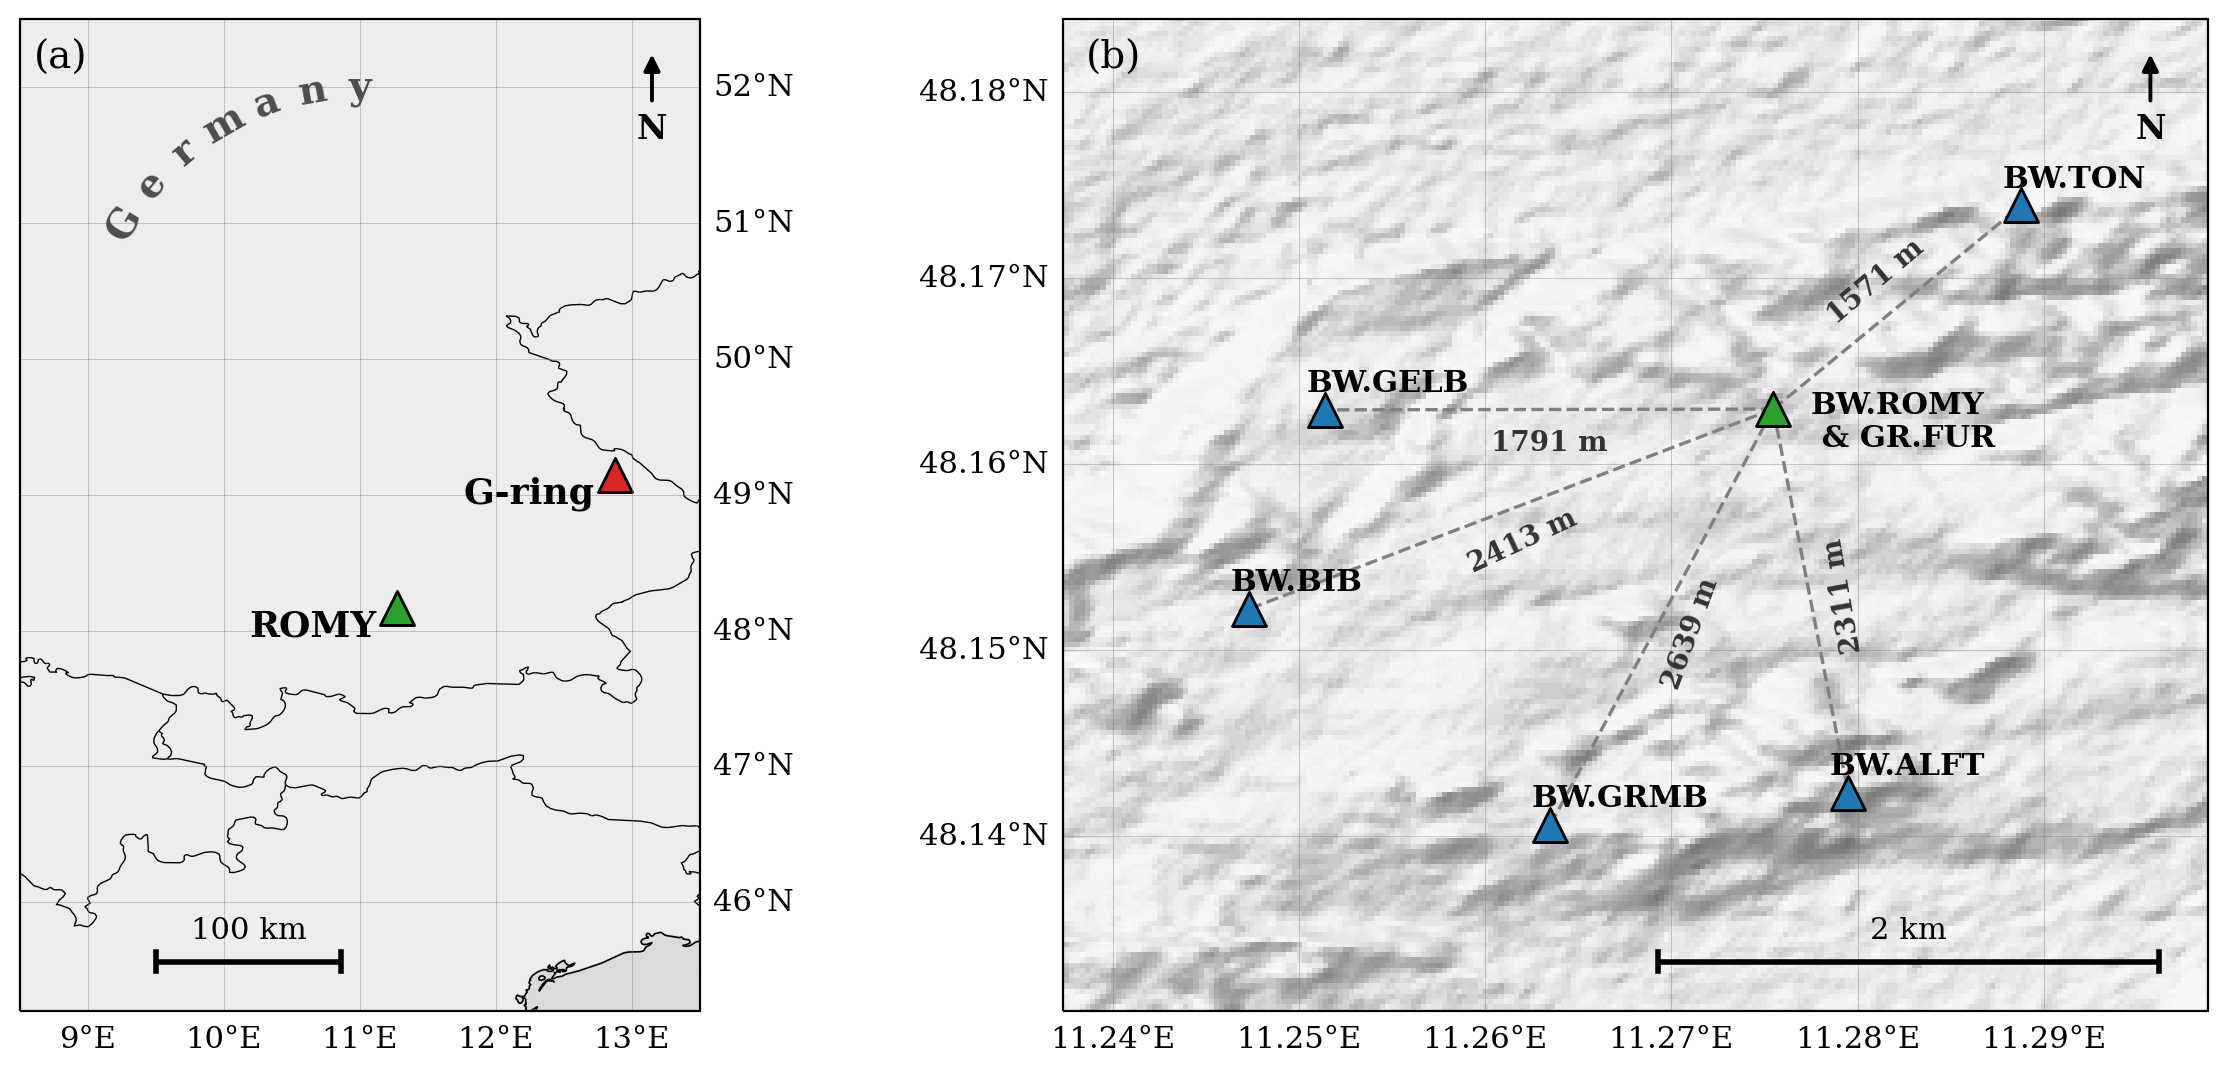

In [10]:
# Optional cartopy support (coastlines/borders)
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    has_cartopy = True
except Exception:
    has_cartopy = False


romy_code, gring_code = stations_a
romy_lat, romy_lon = STATION_COORDS[romy_code]
gring_lat, gring_lon = STATION_COORDS[gring_code]

# Regional frame around ROMY/G-ring
lon0, lon1 = 8.5, 13.5
lat0, lat1 = 47.2, 50.5


# Compute a compact frame for the ROMY array panel
arr_lats = np.array([STATION_COORDS[c][0] for c in array_stations])
arr_lons = np.array([STATION_COORDS[c][1] for c in array_stations])
pad = 0.03
alon0, alon1 = arr_lons.min() - pad, arr_lons.max() + pad
alat0, alat1 = arr_lats.min() - pad, arr_lats.max() + pad

rotations = [40, 25, 70, 0, 100, 0]

fig = plt.figure(figsize=(13, 5.5))

plt.subplots_adjust(wspace=-0.05)


def add_north_arrow(ax, xy=(0.93, 0.90), size=0.08, color="k", fontsize=12):
    """North arrow in axes coordinates (upper-right by default)."""
    ax.annotate(
        "N",
        xy=xy,
        xytext=(xy[0], xy[1] - size),
        xycoords="axes fraction",
        textcoords="axes fraction",
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold",
        color=color,
        arrowprops=dict(arrowstyle="-|>", lw=1.4, color=color),
        zorder=10,
    )


def add_scale_bar_lonlat(ax, length_km, location=(0.73, 0.07), lw=2.0, color="k", fontsize=10):
    """Scale bar for lon/lat axes using local lon-degree conversion."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lat_ref = 0.5 * (y0 + y1)

    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat_ref))
    if km_per_deg_lon <= 0:
        return

    dlon = length_km / km_per_deg_lon

    x_start = x0 + location[0] * (x1 - x0)
    y_bar = y0 + location[1] * (y1 - y0)
    x_end = x_start + dlon

    ax.plot([x_start, x_end], [y_bar, y_bar], color=color, lw=lw, solid_capstyle="butt", zorder=10)
    tick_h = 0.01 * (y1 - y0)
    ax.plot([x_start, x_start], [y_bar - tick_h, y_bar + tick_h], color=color, lw=lw, zorder=10)
    ax.plot([x_end, x_end], [y_bar - tick_h, y_bar + tick_h], color=color, lw=lw, zorder=10)

    ax.text(
        0.5 * (x_start + x_end),
        y_bar + 1.8 * tick_h,
        f"{int(length_km)} km",
        ha="center",
        va="bottom",
        fontsize=fontsize,
        color=color,
        zorder=10,
    )


if has_cartopy:
    proj = ccrs.PlateCarree()

    def _ensure_geoaxes_flags(ax):
        # Compatibility fix for some Cartopy/Matplotlib combinations.
        if not hasattr(ax, "_autoscaleXon"):
            ax._autoscaleXon = True
        if not hasattr(ax, "_autoscaleYon"):
            ax._autoscaleYon = True

    ax1 = fig.add_subplot(1, 2, 1, projection=proj)
    _ensure_geoaxes_flags(ax1)
    ax1.set_extent([lon0, lon1, lat0, lat1], crs=proj)

    ax1.add_feature(cfeature.LAND, facecolor="0.93", edgecolor="none")
    ax1.add_feature(cfeature.OCEAN, facecolor="0.86")
    ax1.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax1.add_feature(cfeature.COASTLINE, linewidth=0.6)
    gl1 = ax1.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    gl1.top_labels = False
    gl1.left_labels = False

    ax1.scatter(romy_lon, romy_lat, s=150, c="tab:green", edgecolors="k", marker="^", transform=proj)
    ax1.scatter(gring_lon, gring_lat, s=150, c="tab:red", edgecolors="k", marker="^", transform=proj)

    ax1.text(gring_lon-0.15, gring_lat-0.002, "G-ring", fontsize=13, transform=proj, ha="right", va="top", fontweight="bold")
    ax1.text(romy_lon-0.15, romy_lat-0.002, "ROMY", fontsize=13, transform=proj, ha="right", va="top", fontweight="bold")

    ax1.set_xlim(lon0, lon1)
    ax1.set_ylim(lat0-2, lat1+2)

    add_curved_country_label(
        ax1,
        "Germany",
        center_lon=11,
        center_lat=50,
        radius_deg=-2,
        theta1=np.deg2rad(270),
        theta0=np.deg2rad(330),
        fontsize=14,
        color="0.3",
        zorder=4,
    )


    ax2 = fig.add_subplot(1, 2, 2, projection=proj)
    _ensure_geoaxes_flags(ax2)
    ax2.set_extent([alon0, alon1, alat0, alat1], crs=proj)
    ax2.add_feature(cfeature.LAND, facecolor="0.95", edgecolor="none")
    ax2.add_feature(cfeature.BORDERS, linewidth=0.4)
    gl2 = ax2.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    gl2.top_labels = False
    gl2.right_labels = False

    c_lat, c_lon = STATION_COORDS[romy_code]

    for code, rotation in zip(array_stations, rotations):
        lat, lon = STATION_COORDS[code]
        color = "tab:green" if code == romy_code else "tab:blue"

        if code != romy_code:
            ax2.plot([c_lon, lon], [c_lat, lat], color="0.5", lw=1.2, ls="--", transform=proj, zorder=2)

            mx, my = 0.5 * (c_lon + lon), 0.5 * (c_lat + lat)
            dx, dy = lon - c_lon, lat - c_lat
            norm = np.hypot(dx, dy) + 1e-12
            ox, oy = -dy / norm, dx / norm
            off = 0.0018

            ax2.text(
                mx + off * ox,
                my + off * oy,
                f"{DIST_M[code]:.0f} m",
                fontsize=10,
                rotation=rotation,
                color="0.2",
                fontweight="bold",
                ha="center",
                va="center",
                transform=proj,
                zorder=6,
            )

        ax2.scatter(lon, lat, s=150, c=color, edgecolors="k", transform=proj, marker="^", zorder=7)
        if code == romy_code:
            ax2.text(lon + 0.002, lat - 0.002, code + "\n & GR.FUR", fontsize=11, transform=proj, fontweight="bold")
        else:
            ax2.text(lon - 0.001, lat + 0.001, code, fontsize=11, transform=proj, fontweight="bold")
        
    ax2.set_ylim(alat0+0.02, alat1-0.02)
    ax2.set_xlim(alon0+0.02, alon1-0.02)

else:
    ax1 = fig.add_subplot(1, 2, 1)
    ax1.set_xlim(lon0, lon1)
    ax1.set_ylim(lat0, lat1)
    ax1.set_xlabel("Longitude (deg)")
    ax1.set_ylabel("Latitude (deg)")
    ax1.tick_params(top=False, right=False, labeltop=False, labelright=False)
    ax1.grid(True, alpha=0.3)
    ax1.scatter(romy_lon, romy_lat, s=150, c="tab:green", edgecolors="k", label="ROMY", fontweight="bold")
    ax1.scatter(gring_lon, gring_lat, s=150, c="tab:red", edgecolors="k", marker="^", label="G-ring", fontweight="bold")
    ax1.legend(loc="lower left")

    ax2 = fig.add_subplot(1, 2, 2)
    ax2.set_xlim(alon0, alon1)
    ax2.set_ylim(alat0+0.01, alat1-0.01)
    ax2.set_xlabel("Longitude (deg)")
    ax2.set_ylabel("Latitude (deg)")
    ax2.tick_params(top=False, right=False, labeltop=False, labelright=False)
    ax2.grid(True, alpha=0.3)

    c_lat, c_lon = STATION_COORDS[romy_code]


    for code in array_stations:
        lat, lon = STATION_COORDS[code]
        color = "tab:green" if code == romy_code else "tab:blue"

        if code != romy_code:
            ax2.plot([c_lon, lon], [c_lat, lat], color="0.25", lw=1.2, ls="--", zorder=2)

            mx, my = 0.5 * (c_lon + lon), 0.5 * (c_lat + lat)
            dx, dy = lon - c_lon, lat - c_lat
            norm = np.hypot(dx, dy) + 1e-12
            ox, oy = -dy / norm, dx / norm
            off = 0.0018

            ax2.text(
                mx + off * ox,
                my + off * oy,
                f"{DIST_M[code]:.0f} m",
                fontsize=10,
                color="0.2",
                fontweight="bold",
                ha="center",
                va="center",
                zorder=6,
            )

        ax2.scatter(lon, lat, s=90, c=color, edgecolors="k", marker="^", zorder=7)
        if code == romy_code:
            ax2.text(lon + 0.001, lat + 0.001, code + "\n & GR.FUR", fontsize=11, fontweight="bold")
        else:
            ax2.text(lon + 0.001, lat + 0.001, code, fontsize=11, fontweight="bold")

add_dem_light_grey(ax2, alpha=0.55)

# North arrows and scale bars
add_north_arrow(ax1, xy=(0.93, 0.97), size=0.08)
add_scale_bar_lonlat(ax1, 100, location=(0.20, 0.05), fontsize=11)

add_north_arrow(ax2, xy=(0.95, 0.97), size=0.08)
add_scale_bar_lonlat(ax2, 2, location=(0.52, 0.05), fontsize=11)

# Panel labels inside each subplot (upper left)
ax1.text(0.02, 0.98, "(a)", transform=ax1.transAxes, ha="left", va="top", fontsize=14)
ax2.text(0.02, 0.98, "(b)", transform=ax2.transAxes, ha="left", va="top", fontsize=14)

plt.tight_layout()
plt.show()


In [11]:
# (optional) save figure
import os
os.makedirs("./output/figures/publication", exist_ok=True)
fig.savefig("./output/figures/publication/romy_array_maps.png", dpi=200, bbox_inches="tight")